# <h1 style="text-align:center">***Gaussian Naive Bayes from Scratch***</h1>
#### Theoretical Foundations of Machine Learning —  **Assignment one**

**Members:**
- Ahmed Mohamed Elsayed Tolba — 20242023
- Mohamed Faisal Mohamed Salem — 20240523

**Dataset:** Breast Cancer Wisconsin

---

## Task 1: Data Preparation

In this task we load the Breast Cancer Wisconsin dataset, inspect its shape and class distribution, and split it into training and test sets.
<br> The split must be stratified, 80% training and 20% testing, with seed 42, so each class keeps the same proportion in both sets.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()
x = data.data
y = data.target
print("="*80)
print("X shape:", x.shape)
print("y shape:", y.shape)
print("Feature names:", data.feature_names[:5])
print("Target names:", data.target_names)
print("Class counts:", np.unique(y, return_counts=True))
print("="*80)
def train_test_split(x, y, test_size=0.2, seed=42):
    rng = np.random.default_rng(seed)
    train_idx = []
    test_idx = []

    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        n_test = int(len(idx) * test_size)
        test_idx.extend(idx[:n_test])
        train_idx.extend(idx[n_test:])

    train_idx = np.array(train_idx)
    test_idx = np.array(test_idx)
    rng.shuffle(train_idx)
    rng.shuffle(test_idx)

    return x[train_idx], x[test_idx], y[train_idx], y[test_idx]

x_train, x_test, y_train, y_test = train_test_split(x, y)
print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("Train class counts:", np.unique(y_train, return_counts=True))
print("Test class counts:", np.unique(y_test, return_counts=True))
print("="*80)

train_mean = x_train.mean(axis=0)
train_std = x_train.std(axis=0)
train_std[train_std == 0] = 1
x_train_scaled = (x_train - train_mean) / train_std
x_test_scaled = (x_test - train_mean) / train_std

print("STANDARDIZATION RESULTS")
print("Original training shape:", x_train.shape)
print("Original testing shape:", x_test.shape)
print("Mean of first 5 scaled features:",x_train_scaled.mean(axis=0)[:5])
print("Standard deviation of first 5 scaled features:",x_train_scaled.std(axis=0)[:5])
print("=" * 80)


X shape: (569, 30)
y shape: (569,)
Feature names: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness']
Target names: ['malignant' 'benign']
Class counts: (array([0, 1]), array([212, 357]))
x_train shape: (456, 30)
x_test shape: (113, 30)
y_train shape: (456,)
y_test shape: (113,)
Train class counts: (array([0, 1]), array([170, 286]))
Test class counts: (array([0, 1]), array([42, 71]))
STANDARDIZATION RESULTS
Original training shape: (456, 30)
Original testing shape: (113, 30)
Mean of first 5 scaled features: [-4.36541641e-15  1.27006105e-15  2.53793088e-15  9.15447055e-16
 -4.78369780e-15]
Standard deviation of first 5 scaled features: [1. 1. 1. 1. 1.]


### Does GNB need feature scaling?

No. Accuracy without scaling was 0.938 (106/113) and accuracy with scaling was 0.929 (105/113), a difference of only 0.009, or 1 test sample. This is because GNB estimates a separate mean and variance for each feature in each class, so rescaling a feature rescales its Gaussian parameters in the same way for both classes and does not change which class has the larger log score in any important way.

---

## Task 2: Gaussian Naive Bayes Implementation

We implement the classifier from scratch. Training means estimating, for each class and each feature, a prior, a mean and a variance. Prediction means computing,
<br> for each test sample and each class, a log score, and picking the class with the largest score. We work in log space to avoid underflow.

In [2]:
class GaussianNaiveBayes:
    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, x, y):
        n_samples, n_features = x.shape
        self.classes = np.unique(y)
        n_classes = len(self.classes)

        self.theta = np.zeros((n_classes, n_features))
        self.var = np.zeros((n_classes, n_features))
        self.class_prior = np.zeros(n_classes)

        for i, c in enumerate(self.classes):
            x_c = x[y == c]
            self.theta[i] = x_c.mean(axis=0)
            self.var[i] = x_c.var(axis=0)
            self.class_prior[i] = x_c.shape[0] / n_samples

        epsilon = self.var_smoothing * np.var(x, axis=0).max()
        self.var = self.var + epsilon
        return self
    
    def _joint_log_likelihood(self, x):
        log_prior = np.log(self.class_prior)
        diff = x[:, None, :] - self.theta
        log_prob = -0.5 * np.log(2 * np.pi * self.var) - (diff ** 2) / (2 * self.var)
        return log_prior + log_prob.sum(axis=2)
    
    def predict(self, x):
        log_joint = self._joint_log_likelihood(x)
        return self.classes[np.argmax(log_joint, axis=1)]
    
    def predict_proba(self, x):
        log_joint = self._joint_log_likelihood(x)
        log_joint = log_joint - log_joint.max(axis=1, keepdims=True)
        proba = np.exp(log_joint)
        return proba / proba.sum(axis=1, keepdims=True)

model = GaussianNaiveBayes()
model.fit(x_train, y_train)
print("classes_:", model.classes)
print("class_prior_:", model.class_prior)
print("theta_ shape:", model.theta.shape)
print("var_ shape:", model.var.shape)
print("theta for malignant first 3 features:", model.theta[0, :3])

y_pred = model.predict(x_test)
print("y_pred first 10:", y_pred[:10])
print("y_test first 10:", y_test[:10])
print("Accuracy (quick check):", (y_pred == y_test).mean())

classes_: [0 1]
class_prior_: [0.37280702 0.62719298]
theta_ shape: (2, 30)
var_ shape: (2, 30)
theta for malignant first 3 features: [ 17.366       21.67541176 114.65817647]
y_pred first 10: [0 0 1 1 1 1 0 1 1 1]
y_test first 10: [0 0 1 1 1 1 0 1 1 1]
Accuracy (quick check): 0.9380530973451328


### Task one question code 


In [3]:
model_unscaled = GaussianNaiveBayes()
model_unscaled.fit(x_train, y_train)
acc_unscaled = (model_unscaled.predict(x_test) == y_test).mean()

model_scaled = GaussianNaiveBayes()
model_scaled.fit(x_train_scaled, y_train)
acc_scaled = (model_scaled.predict(x_test_scaled) == y_test).mean()

print("Accuracy without scaling:", acc_unscaled)
print("Accuracy with scaling:", acc_scaled)

Accuracy without scaling: 0.9380530973451328
Accuracy with scaling: 0.9292035398230089


### Sanity Test

We test the classifier on a tiny dataset we made by hand, with 2 classes and 1 feature, so we can calculate the mean, variance and one posterior with a calculator and check that our class gives the same numbers.

In [4]:
x_sanity = np.array([[1], [2], [3], [5], [6], [7]])
y_sanity = np.array([0, 0, 0, 1, 1, 1])

tiny_model = GaussianNaiveBayes()
tiny_model.fit(x_sanity, y_sanity)

print("classes:", tiny_model.classes)
print("class_prior:", tiny_model.class_prior)
print("theta:", tiny_model.theta)
print("var:", tiny_model.var)
print("Prediction for 2.5:", tiny_model.predict(np.array([[2.5]])))
print("Probabilities for 2.5:", tiny_model.predict_proba(np.array([[2.5]])))

classes: [0 1]
class_prior: [0.5 0.5]
theta: [[2.]
 [6.]]
var: [[0.66666667]
 [0.66666667]]
Prediction for 2.5: [0]
Probabilities for 2.5: [[9.99876605e-01 1.23394577e-04]]


## Task 3: Evaluation Metrics from Scratch

### 1- accuracy

In [5]:
def accuracy(y_true, y_pred):
    return np.mean(y_pred == y_true)

### 2- confusion_matrix
#### TN  FP
#### FN  TP

In [6]:
def confusion_matrix(y_true, y_pred, classes):
    k = len(classes)
    res = np.zeros((k,k), dtype=int)
    for i, r in enumerate(classes):
        for j, c in enumerate(classes):
            res[i][j] = np.sum((r == y_true) & (c == y_pred))

    return res

### 3- precision_recall_f1

In [7]:
def precision_recall_f1(y_true, y_pred, classes):
    cm = confusion_matrix(y_true, y_pred, classes)
    tp = np.diag(cm)
    fp_plus_tp = np.sum(cm, axis=0)
    fn_plus_tp = np.sum(cm, axis = 1)
    precision = np.where(fp_plus_tp > 0, tp / fp_plus_tp, 0.0)
    recall = np.where(fn_plus_tp > 0, tp / fn_plus_tp, 0.0)

    f1 = np.where((precision + recall) > 0, 2 * precision * recall / (precision + recall), 0.0)
    
    macro_precision = float(np.mean(precision))
    macro_recall = float(np.mean(recall))
    macro_f1 = float(np.mean(f1))

    prf = {
        "precision": precision,
        "recall": recall,
        "f1": f1
    }
    macro_prf = {
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    }
    return prf , macro_prf

In [8]:
classes = np.unique(y_train)
y_pred = model.predict(x_test)

acc = accuracy(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, classes)
prf, macro = precision_recall_f1(y_test, y_pred, classes)

print("Accuracy:", acc)
print("Confusion matrix:\n", cm)
for i, name in enumerate(data.target_names):
    print(f"{name}: precision={prf['precision'][i]:.3f}, "
          f"recall={prf['recall'][i]:.3f}, f1={prf['f1'][i]:.3f}")
print("Macro:", macro)

Accuracy: 0.9380530973451328
Confusion matrix:
 [[38  4]
 [ 3 68]]
malignant: precision=0.927, recall=0.905, f1=0.916
benign: precision=0.944, recall=0.958, f1=0.951
Macro: {'macro_precision': 0.9356368563685638, 'macro_recall': 0.9312541918175721, 'macro_f1': 0.9333558008256804}


### 4- matplotlib heat-map

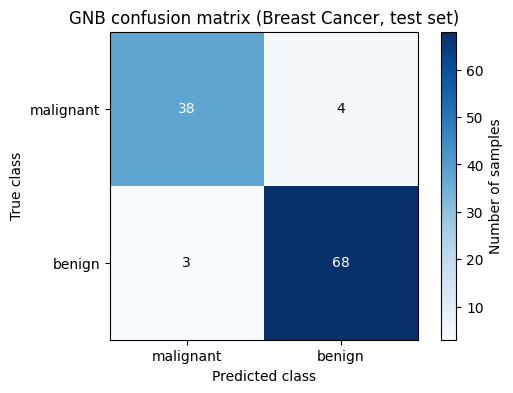

In [9]:
def plot_confusion_matrix(cm, class_names, title):
    fig, ax = plt.subplots(figsize=(6, 4))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(class_names)))
    ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels(class_names)
    ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_title(title)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    fig.colorbar(im, ax=ax, label="Number of samples")
    plt.show()

plot_confusion_matrix(cm, data.target_names, "GNB confusion matrix (Breast Cancer, test set)")

## Task4: Experiments

In [10]:
model = GaussianNaiveBayes()
acc = -1e9
inx = 0
for i in range(x_train.shape[1]):
    model.fit(x_train[:,[i]], y_train)
    if (model.predict(x_test[:,[i]]) == y_test).mean() > acc:
        acc = (model.predict(x_test[:,[i]]) == y_test).mean()
        inx = i

print("Accuracy:", acc, "\nstrongly informative feature:", data.feature_names[inx]) #inx = 27 -> worst concave points


Accuracy: 0.9292035398230089 
strongly informative feature: worst concave points


In [11]:
copies = [0, 1, 3, 5, 10]

accs, confs = [], []
model = GaussianNaiveBayes()
for i in copies:
    rep_train = np.repeat(x_train[:, [inx]], i, axis = 1)
    x_train_new = np.hstack([x_train, rep_train])
    rep_test = np.repeat(x_test[:, [inx]], i, axis = 1)
    x_test_new = np.hstack([x_test, rep_test])
    model.fit(x_train_new, y_train)
    accs.append((model.predict(x_test_new) == y_test).mean())
    confs.append(model.predict_proba(x_test_new).max(axis=1).mean())

    print("copies:", i, "\naccuracy:", accs[-1], "\nconfidence:", confs[-1])

copies: 0 
accuracy: 0.9380530973451328 
confidence: 0.9928143507235552
copies: 1 
accuracy: 0.9292035398230089 
confidence: 0.9953902448831697
copies: 3 
accuracy: 0.9292035398230089 
confidence: 0.9990859398450969
copies: 5 
accuracy: 0.9292035398230089 
confidence: 0.998888262363141
copies: 10 
accuracy: 0.9380530973451328 
confidence: 0.9927680571742425


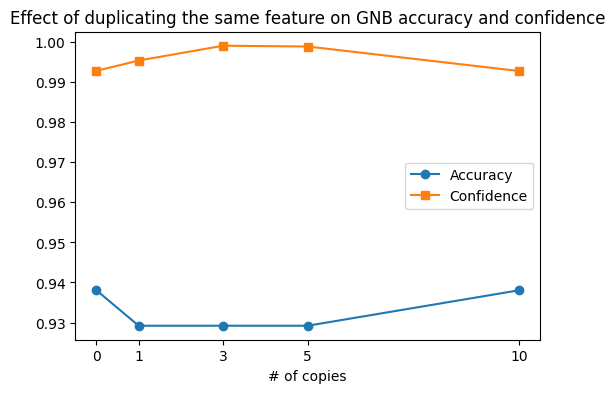

In [16]:
plt.figure(figsize=(6, 4))
plt.plot(copies, accs, marker="o", label="Accuracy")
plt.plot(copies, confs, marker="s", label="Confidence")
plt.xlabel("# of copies")
plt.title("Effect of duplicating the same feature on GNB accuracy and confidence")
plt.xticks(copies)
plt.legend()
plt.show()

### Explain what happens to the model's confidence.

#### At 1 copy confidence increased while accuracy decreased
#### At 3 copies confidence peaked while accuracy remained unchanged
#### At 5 copies confidence decreased while accuracy increased 
#### at 10 copies confidence decreased further while accuracy increased again
#### This shows that artificial confidence shifts caused by duplicating the same feature do not guarantee an increase in accuracy

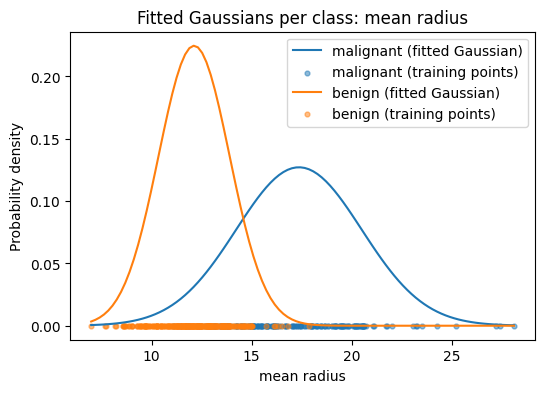

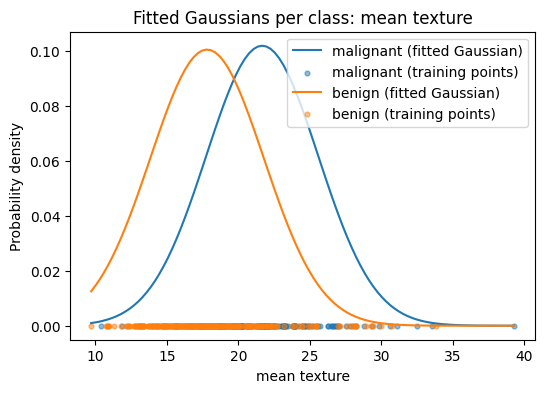

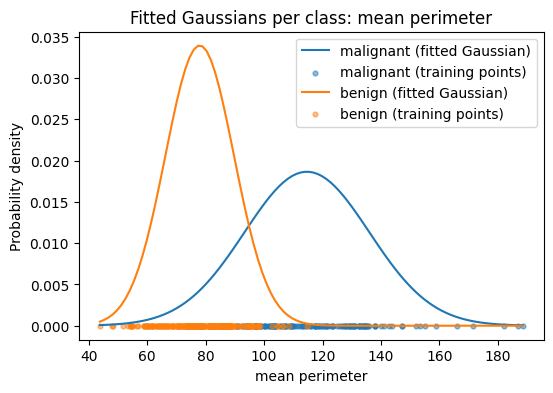

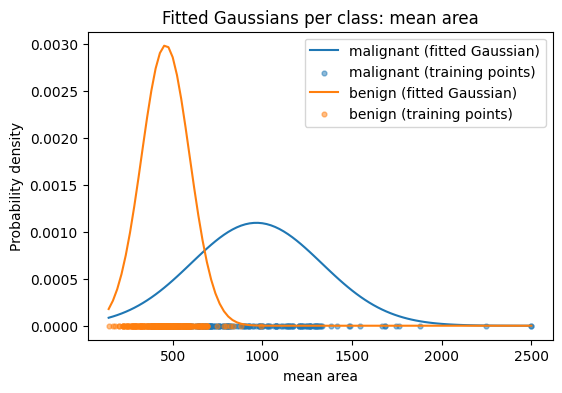

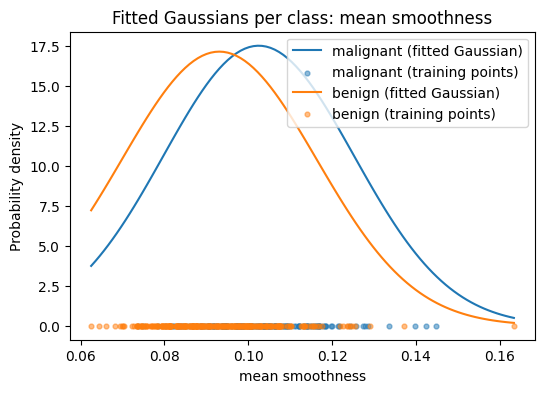

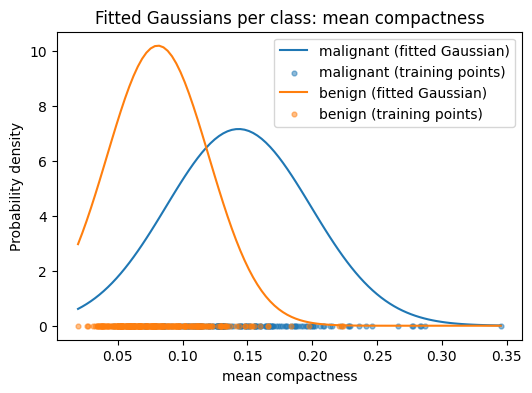

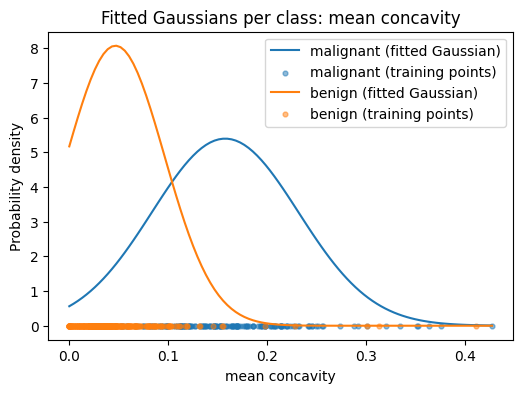

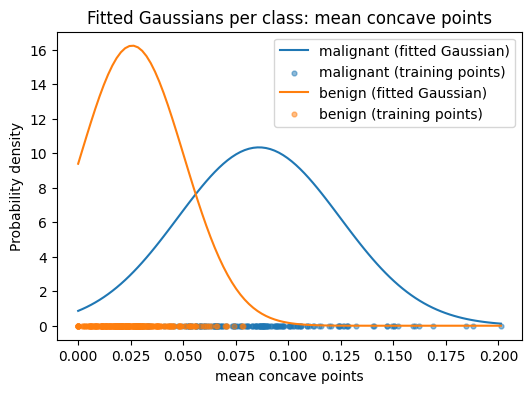

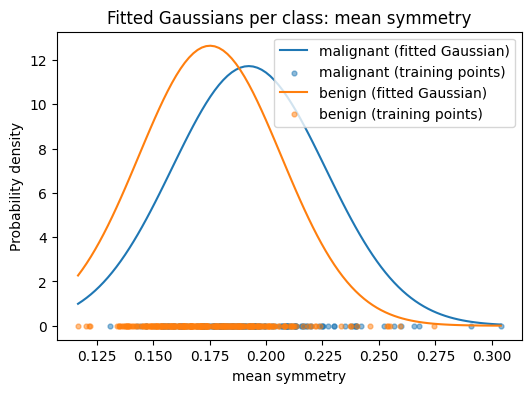

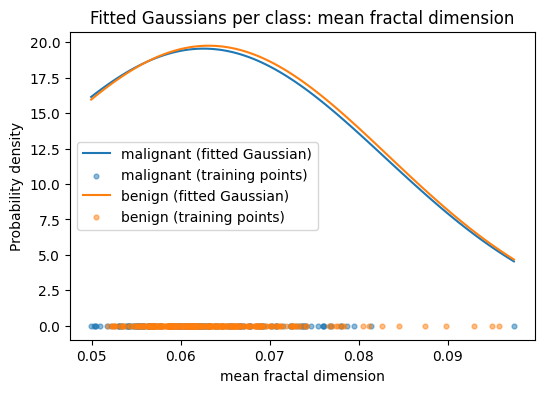

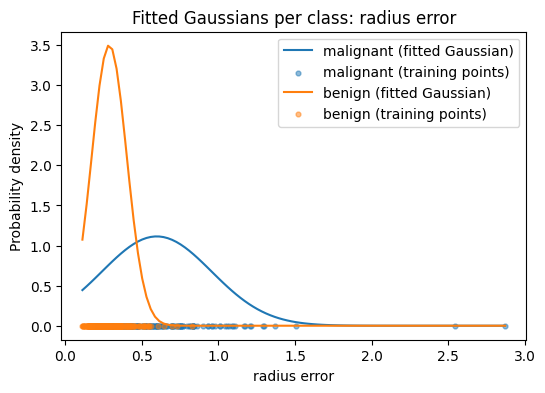

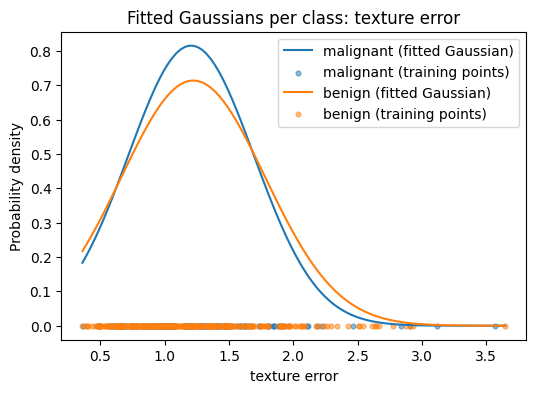

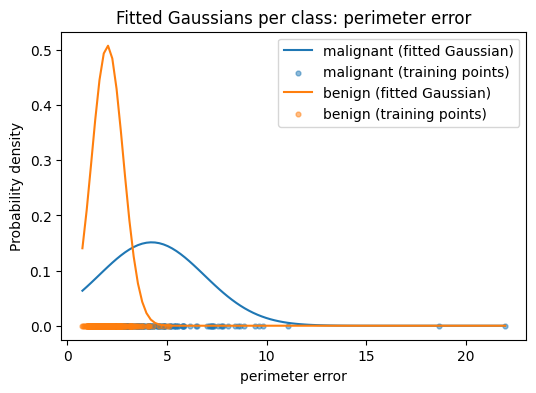

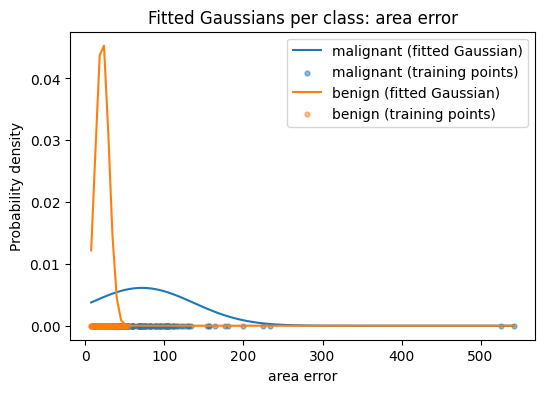

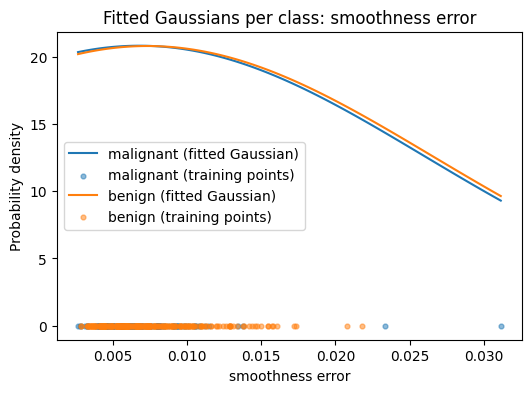

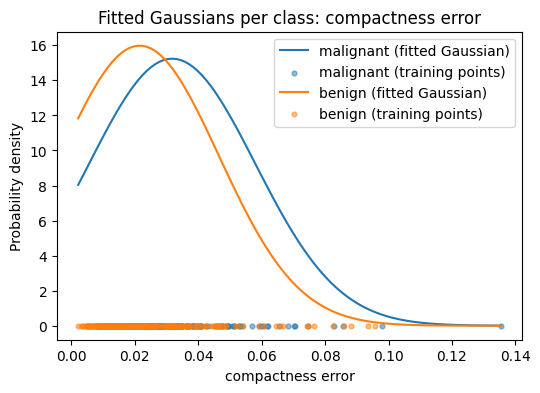

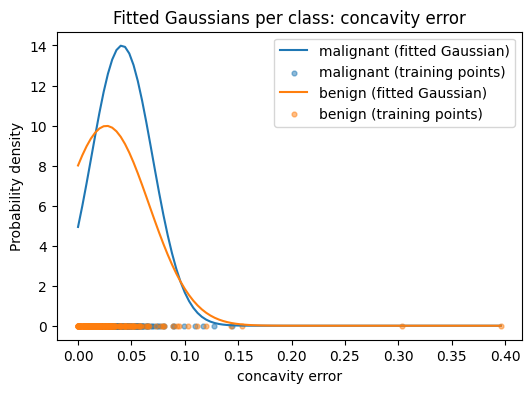

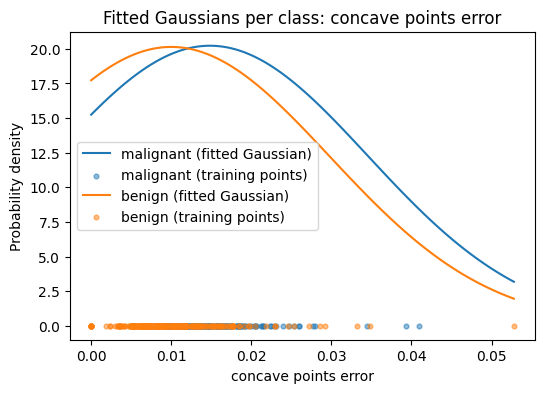

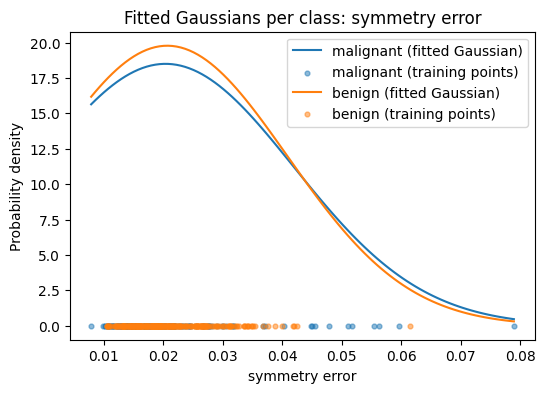

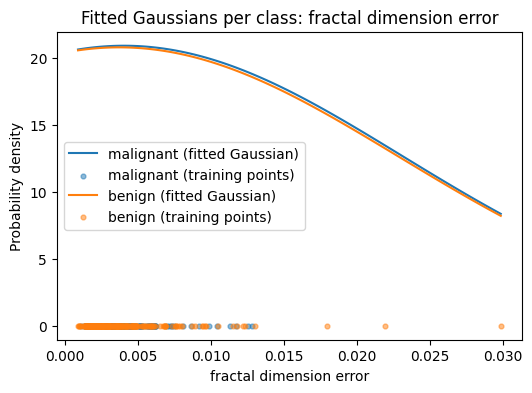

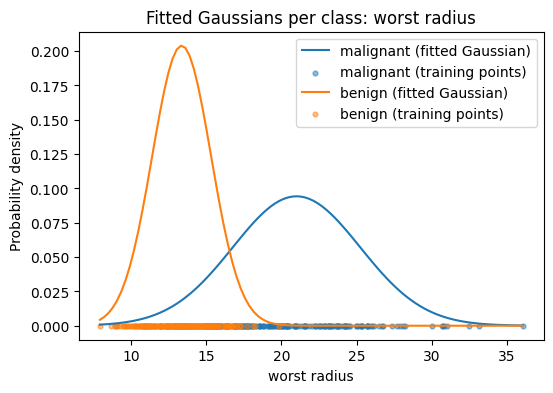

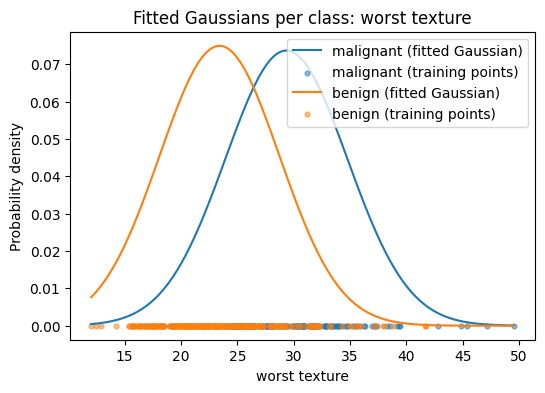

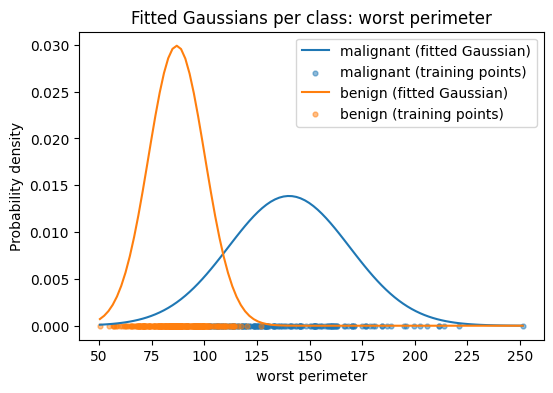

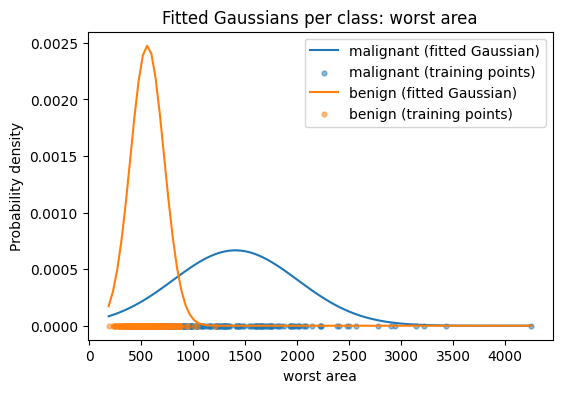

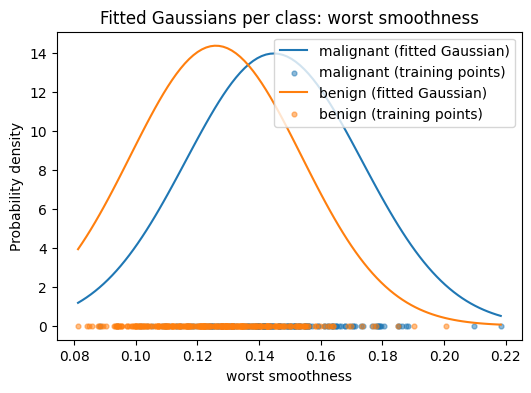

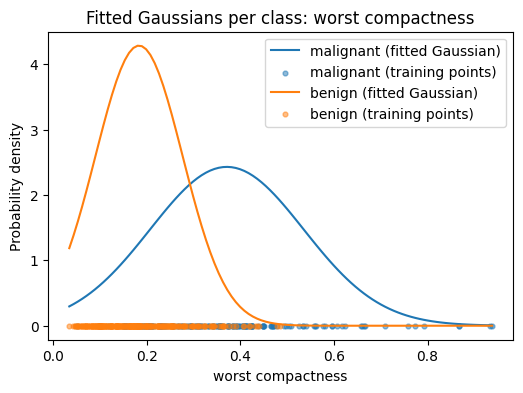

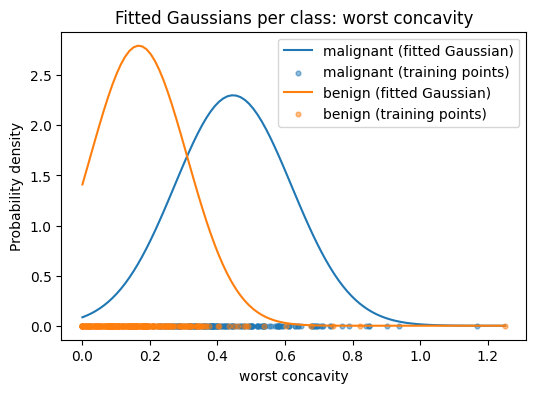

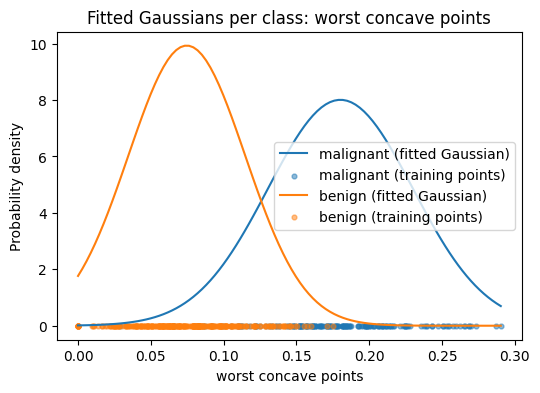

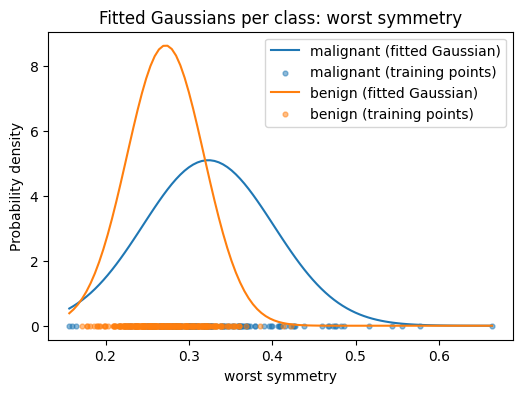

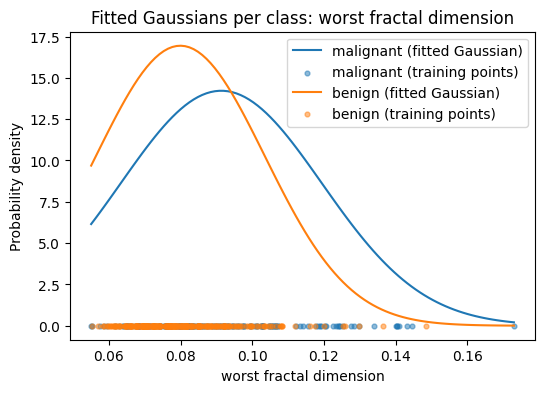

In [13]:
model = GaussianNaiveBayes().fit(x_train, y_train)

def plot_feature_gaussians(model, x_train, y_train, j, feature_names, class_names):
    xs = np.linspace(x_train[:, j].min(), x_train[:, j].max(), 100)
    plt.figure(figsize=(6, 4))
    for i, c in enumerate(model.classes):
        mean_value, var = model.theta[i, j], model.var[i, j]
        probability_density = np.exp(-(xs - mean_value) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)
        
        plt.plot(xs, probability_density, label=f"{class_names[c]} (fitted Gaussian)")
        training_points = x_train[y_train == c, j]
        y_zeros = np.zeros_like(training_points)
        plt.scatter(training_points, y_zeros, s=12, alpha=0.5, label=f"{class_names[c]} (training points)")
    plt.title(f"Fitted Gaussians per class: {feature_names[j]}")
    plt.xlabel(feature_names[j])
    plt.ylabel("Probability density")
    plt.legend()
    plt.show()

for j in range(x_train.shape[1]):
    plot_feature_gaussians(model, x_train, y_train, j, data.feature_names, data.target_names)

In [14]:
x_train_2d = x_train[:, [0, 1]]
x_test_2d = x_test[:, [0, 1]]
model = GaussianNaiveBayes()
model.fit(x_train_2d, y_train)

x_min = x_train_2d[:, 0].min() 
x_max = x_train_2d[:, 0].max() 
y_min = x_train_2d[:, 1].min() 
y_max = x_train_2d[:, 1].max() 

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)
grid = np.column_stack((xx.ravel(), yy.ravel()))

pred = model.predict(grid)
pred = pred.reshape(xx.shape)

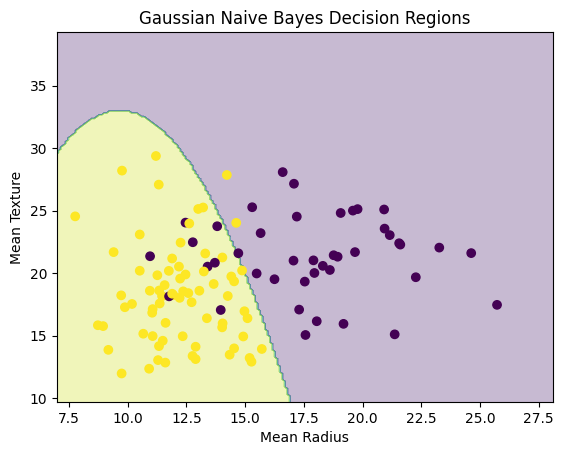

In [15]:
plt.contourf(xx, yy, pred, alpha=0.3)

plt.scatter(
    x_test_2d[:, 0],
    x_test_2d[:, 1],
    c=y_test
)
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Gaussian Naive Bayes Decision Regions")
plt.show()

### Describe in two sentences why the decision boundaries are curved and not straight lines.

it produces curved decision boundaries because its Gaussian equation contains quadratic terms involving the feature values.
When the variances differ between classes these terms (quadratic) generally do not cancel out resulting in curved rather than straight decision boundaries.

## Task7

### Q1) Why is the classifier called "naive"? Give an example where the assumption is clearly false.
It is called naive because it assumes that all features are independent given the class, likelihood split into a product of probability of each feature given y P(x | y) = P(x1 | y) * P(x2 | y)  *... * P(xd | y). This is a strong simplification because in real data features usually influence each other. 
For example, in a Breast Cancer dataset mean radius and mean area are related.

### Q2) Why can we ignore P(x) when predicting the class?
Bayes' theorem law -> P(y | x) = (P(x | y) · P(y)) / P(x). The denominator P(x) is the same for every class y because it does not depend on y. Because prediction only takes the argmax over classes, dividing every class score by the same positive constant does not change which class is the largest.

### Q3) What happens if a feature has zero variance within a class and there is no smoothing?
GNB law -> P(x|y) = exp(-((mu-x)^2)/(2*sigma^2))/Root(2*PI*sigma^2). We observe that the denominator is equal zero if a feature has zero variance. Then Gaussian PDF becomes undefined due to division by zero. 

### Q4) How is GNB related to Quadratic Discriminant Analysis (QDA)? What extra assumption does GNB make?

Gaussian naive bayes is a simplified version of Quadratic Discriminant Analysis, both assume that features follow Gaussian distribution within each class.
extra assumption does GNB make is that features are conditionally independent given class.

### Q5) GNB trains in one pass over the data. What is its time complexity for training and for predicting one sample (in n, d and k)?
The training time complexity of GNB is \(O(nd)\), because it processes n samples and d features to calculate the mean and variance for each class. The prediction time complexity for one sample is \(O(kd)\), because it calculates the likelihood across d features for each of the k classes.